# NOAA IBTrACS: inspect a tropical cyclone track

IBTrACS v04r01 combines best tracks from different agencies. This example selects Hurricane Milton (SID `2024279N21265`) from NOAA's rolling `last3years` subset and preserves the original observation fields. The subset changes over time; its version does not pin its bytes. Record the SHA-256 and retain the downloaded snapshot for reproducibility. Basin subsets can overlap, and recent tracks may be provisional. Track points and reported storm winds are not asset winds, return-period curves, or impacts. Wind averaging periods can differ by agency; consult the [NOAA documentation](https://www.ncei.noaa.gov/products/international-best-track-archive) before comparing values.

The companion pipeline is `pipelines/ibtracs_pipeline.py`. It downloads the full selected CSV, then streams filtered rows into Parquet; filtering does not reduce the download size.

Run from a local crc-docs checkout: use `uv sync`, then launch Jupyter with
`uv run jupyter lab` and select the project kernel. The first pipeline run
requires internet access.


In [1]:
# Check the local notebook environment before running the pipeline.
import importlib.util
import subprocess
import sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
if IN_COLAB or importlib.util.find_spec("crc_sdk") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet",
                           "--disable-pip-version-check", "plotly>=6", "crc-sdk>=0.11.1,<1"])
root = next((folder for folder in (Path.cwd(), *Path.cwd().parents)
             if (folder / "pipelines").is_dir()), None)
if root is None:
    raise RuntimeError("Run this notebook from a crc-docs checkout (the pipelines folder is required).")
sys.path.insert(0, str(root))

import os

import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
pio.templates.default = "plotly_white"
pio.defaults.default_width = 1000
pio.defaults.default_height = 470
from pipelines.ibtracs_pipeline import run
import pyarrow.parquet as pq

output = root / "pipeline_output" / "ibtracs"
summary = run(output, "2024279N21265")
print("Track points:", summary["track_points"])
print("Snapshot SHA-256:", summary["source"]["sha256"])
print("Retrieved:", summary["source"]["retrieved_at"])

Track points: 62
Snapshot SHA-256: f587c0d08589afac138c1026b89aafb91887a9c9b4d06c33c602f4304fbdaed6
Retrieved: 2026-11-05T23:02:15.750863+00:00


In [2]:
track = pq.read_table(output / "track.parquet", columns=["SID", "ISO_TIME", "LAT", "LON", "USA_WIND", "USA_PRES"])
print("Units:", {key: summary["source"]["units"][key] for key in ["LAT", "LON", "USA_WIND", "USA_PRES"]})
track.slice(0, 5).to_pandas()

Units: {'LAT': 'degrees_north', 'LON': 'degrees_east', 'USA_WIND': 'kts', 'USA_PRES': 'mb'}


,SID,ISO_TIME,LAT,LON,USA_WIND,USA_PRES
0,2024279N21265,2024-10-04 18:00:00,21.0,-94.6,30,1009
1,2024279N21265,2024-10-04 21:00:00,20.8,-94.9,30,1009
2,2024279N21265,2024-10-05 00:00:00,20.8,-95.2,30,1008
3,2024279N21265,2024-10-05 03:00:00,21.0,-95.3,30,1008
4,2024279N21265,2024-10-05 06:00:00,21.4,-95.4,30,1008


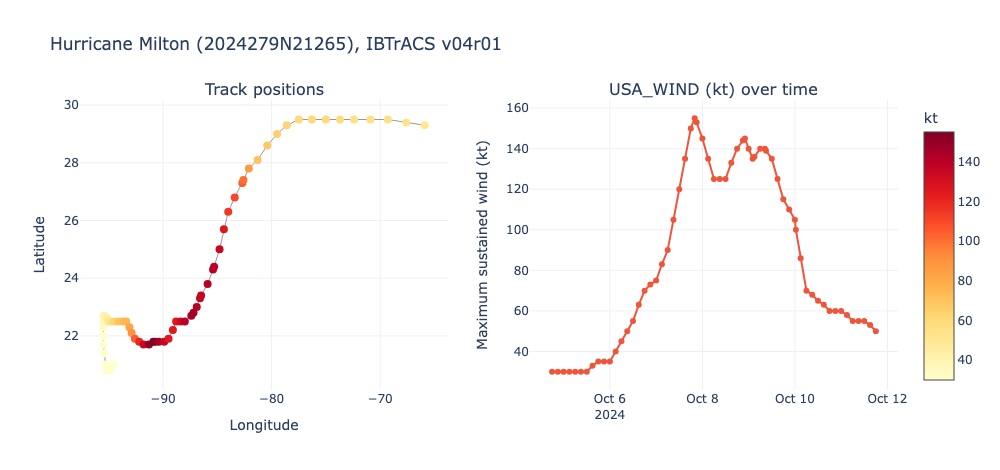

In [3]:
import pandas as pd

# Track positions coloured by wind, and the wind history (knots, US agency).
points = track.to_pandas()
points["USA_WIND"] = pd.to_numeric(points["USA_WIND"])
points["ISO_TIME"] = pd.to_datetime(points["ISO_TIME"])
fig = make_subplots(rows=1, cols=2, subplot_titles=("Track positions", "USA_WIND (kt) over time"))
fig.add_trace(go.Scatter(x=points["LON"].astype(float), y=points["LAT"].astype(float), mode="markers+lines",
                         line=dict(color="#999999", width=1),
                         marker=dict(color=points["USA_WIND"], colorscale="YlOrRd", size=8,
                                     colorbar=dict(title="kt", x=1.02))), row=1, col=1)
fig.add_trace(go.Scatter(x=points["ISO_TIME"], y=points["USA_WIND"], mode="lines+markers"), row=1, col=2)
fig.update_xaxes(title_text="Longitude", row=1, col=1)
fig.update_yaxes(title_text="Latitude", row=1, col=1)
fig.update_yaxes(title_text="Maximum sustained wind (kt)", row=1, col=2)
fig.update_layout(title="Hurricane Milton (2024279N21265), IBTrACS v04r01", showlegend=False, margin=dict(r=90))
fig.show()


Values are NOAA's strings and blank fields are null. `USA_WIND` is the US agency's reported maximum sustained wind in knots, not a wind speed at a particular asset. The snapshot manifest records the exact source URL, retrieval time, HTTP validators and checksum. When the rolling subset no longer includes this storm, select a suitable basin or the full archive instead.